# clock/11 — goal heads vs decision/impulse heads

Third dissociation test (after `09.1` goal-vs-gaze and `10` goal-vs-FV): are the **goal heads**
(trained GoalScope / head-mask set) and the **decision / impulse heads** (completion mask,
`sl→ml` move-on signal) the same population doing the same job?

1. **Load + visualize** both head sets and their overlap (loaders copied from `09.1`, overlap
   table style from `10`).
2. **Do decision heads work as goal heads?** — `apply_goalscope` with **only** `selected_heads`
   swapped (decision vs goal), on *two* prompts: the `10 §3b` code prompt and a native
   `build_example` conditions prompt.
3. **Do goal heads work as decision heads?** — the `09.1 §2a` move-on transplant with the mask
   swapped (decision vs goal). Three readouts: generation, next-token, gaze/attention.
4. **Scale-up** — LATER, only if §2/§3 look promising.

Note on head counts: decision (**181** @0.8) vs goal (**122** @0.9, band 25–55) are not matched;
transplant capacity scales with head count, so treat cross-arm magnitudes as indicative, not
calibrated. No random baseline yet — this is a straight goal-vs-decision dissociation.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, json, random, logging
sys.path.append("../..")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "2,3,4")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import torch
from pathlib import Path
from rich.console import Console
from rich.theme import Theme
from rich.table import Table
from rich.markup import escape
from src.utils import logging_utils, env_utils
logging_utils.configure(level=logging.INFO)
logger = logging.getLogger(__name__)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

In [2]:
from src.models import ModelandTokenizer
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
N_LAYER = mt.n_layer
N_HEADS = mt.model.config.num_attention_heads
print(f"n_layer={N_LAYER}  n_embd={mt.n_embd}  n_heads={N_HEADS}")

2026-07-20 15:11:56 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models
2026-07-20 15:11:56 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-20 15:11:56 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-07-20 15:11:56 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-20 15:11:56 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-07-20 15:11:56 ht

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-07-20 15:12:19 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-20 15:12:19 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-07-20 15:12:20 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64  n_embd=5120  n_heads=40


## 1. Head sets — goal vs decision/impulse

Loaders copied verbatim from `09.1` (cells 4 and 15). The decision mask is trained over
**all** layers (`L0-64`) with `patch_tokens=[-2]`, so `mean_src` below spans every layer — which is
what makes the §3 head-set swap a one-liner.

In [3]:
from src.goals.head_loc_attn import HeadMask
from src.goals.oid_gaze import cache_root

VERSION = "conditions"

# ── goal heads (trained mask @0.9, 32B band 25-55) — copied from 09.1 cell 4 ──
GOAL_THRESHOLD = 0.9
GOAL_BAND = (25, 56)
gck = torch.load(os.path.join(env_utils.DEFAULT_RESULTS_DIR,
                 f"localization/{MODEL_NAME.split('/')[-1]}/lam20/head_mask.pt"), map_location="cpu")
goal_layers = [int(x) for x in gck["layers"]]
gmask = gck["mask_values"].numpy().copy()
gmask[:GOAL_BAND[0]] = 0; gmask[GOAL_BAND[1]:] = 0
goal_heads = [(goal_layers[li], int(h)) for li, h in np.argwhere(gmask > GOAL_THRESHOLD)]
print(f"goal heads (@{GOAL_THRESHOLD}, band {GOAL_BAND[0]}-{GOAL_BAND[1]-1}): {len(goal_heads)}")

goal heads (@0.9, band 25-55): 122


In [4]:
# ── decision / impulse heads (completion mask, tag lam10.0) — copied from 09.1 cell 15 ──
COMPLETION_MASK_ROOT = os.path.join(cache_root(MODEL_NAME, VERSION), "completion_mask")
COMPLETION_MASK_TAG  = "lam10.0"
SEL_THRESHOLD        = 0.8

def _list_masks():
    return sorted([(t, os.path.join(COMPLETION_MASK_ROOT, t), os.path.getmtime(os.path.join(COMPLETION_MASK_ROOT, t)))
                   for t in os.listdir(COMPLETION_MASK_ROOT)
                   if os.path.isdir(os.path.join(COMPLETION_MASK_ROOT, t))], key=lambda x: x[2], reverse=True)
_m = [it for it in _list_masks() if COMPLETION_MASK_TAG in it[0]]
assert _m, f"no completion_mask under {COMPLETION_MASK_ROOT} with tag {COMPLETION_MASK_TAG!r}"
DCK = torch.load(os.path.join(_m[0][1], "mask.pt"), map_location="cpu", weights_only=False)
dec_layers = [int(x) for x in DCK["layers"]]
dmv = DCK["mask_values"].numpy()
decision_heads = [(dec_layers[li], int(h)) for li, h in np.argwhere(dmv > SEL_THRESHOLD)]
PATCH_POS = int(DCK["patch_tokens"][0]) if len(DCK.get("patch_tokens", [-2])) == 1 else -2
print(f"decision heads: {len(decision_heads)} (thr {SEL_THRESHOLD}) · layers {min(dec_layers)}-{max(dec_layers)} · PATCH_POS={PATCH_POS}")

gset, dset = set(goal_heads), set(decision_heads)

def get_mask_bin(heads):
    """HeadMask (CPU) with 1.0 for `heads`, 0.0 elsewhere; layer index space = all layers."""
    hm = HeadMask(mt.n_layer, mt.config.num_attention_heads)
    with torch.no_grad():
        hm.values.zero_()
        for (l, h) in heads:
            hm.values[l, h] = 1.0
    return hm

decision heads: 181 (thr 0.8) · layers 0-63 · PATCH_POS=-2


In [5]:
# ── move-on (sl) mean o_proj-input signal at PATCH_POS, over N sources — copied from 09.1 cell 16 ──
from src.goals.completion_pairs import build_completion_pairs
from src.goals.head_loc_attn import get_o_proj_inputs_batch

N_MEAN_SRC, MEAN_BATCH = 256, 16
src_pairs = build_completion_pairs(mt, n_pairs=N_MEAN_SRC, direction="sl->ml", same=True,
                                   patch_tokens=(PATCH_POS,), seed=1234, log=logger.info)
src_prompts = [p.source.sl_prompt for p in src_pairs]        # "moved-on" sources
acc = {l: [] for l in dec_layers}
for i in range(0, len(src_prompts), MEAN_BATCH):
    batch = src_prompts[i:i + MEAN_BATCH]
    cache = get_o_proj_inputs_batch(mt, batch, dec_layers, token_positions=[PATCH_POS])
    for l in dec_layers: acc[l].append(cache[l][:, 0, :].float().cpu())    # (b, n_embd)
mean_src = torch.stack([torch.cat(acc[l], 0).mean(0) for l in dec_layers])  # (n_dec_layers, n_embd)
print("mean move-on signal:", tuple(mean_src.shape))

2026-07-20 15:12:33 __main__ INFO       built 25/256 pairs (27 attempts)
2026-07-20 15:12:41 __main__ INFO       built 50/256 pairs (53 attempts)
2026-07-20 15:12:50 __main__ INFO       built 75/256 pairs (81 attempts)
2026-07-20 15:12:59 __main__ INFO       built 100/256 pairs (107 attempts)
2026-07-20 15:13:08 __main__ INFO       built 125/256 pairs (135 attempts)
2026-07-20 15:13:16 __main__ INFO       built 150/256 pairs (160 attempts)
2026-07-20 15:13:24 __main__ INFO       built 175/256 pairs (185 attempts)
2026-07-20 15:13:32 __main__ INFO       built 200/256 pairs (210 attempts)
2026-07-20 15:13:40 __main__ INFO       built 225/256 pairs (235 attempts)
2026-07-20 15:13:48 __main__ INFO       built 250/256 pairs (260 attempts)
2026-07-20 15:13:50 __main__ INFO     built 256 pairs from 266 attempts
mean move-on signal: (64, 5120)


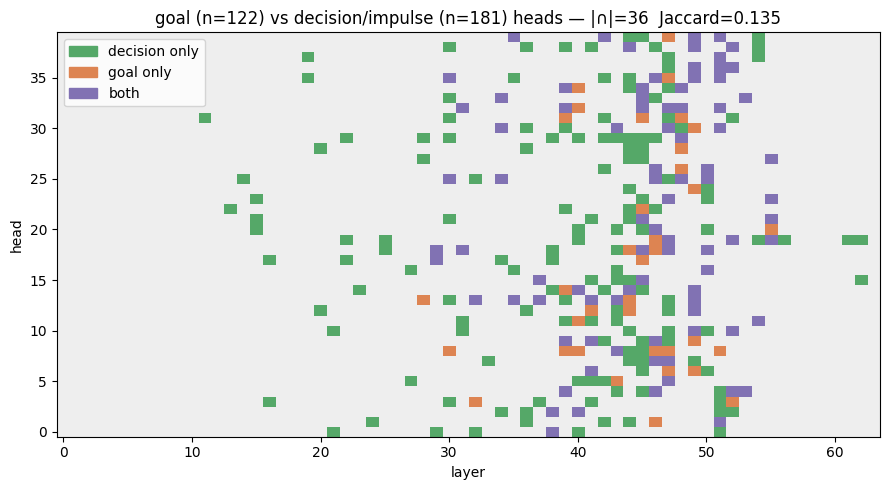

    goal vs decision head overlap     
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ metric                     ┃ value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ goal heads                 │   122 │
│ decision heads             │   181 │
│ intersection               │    36 │
│ union                      │   267 │
│ Jaccard                    │ 0.135 │
│ % of goal that is decision │ 29.5% │
│ % of decision that is goal │ 19.9% │
└────────────────────────────┴───────┘

In [7]:
# ── goal <-> decision head overlap — plot copied from 09.1 cell 17, table style from 10 §3a ──
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

grid = np.zeros((N_LAYER, N_HEADS))
for l, h in dset: grid[l, h] = 1
for l, h in gset: grid[l, h] = 2 if (l, h) in dset else 3
inter, union = gset & dset, gset | dset

fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(grid.T, aspect="auto", origin="lower", vmin=0, vmax=3,
          cmap=ListedColormap(["#eeeeee", "#55a868", "#dd8452", "#8172b3"]))
ax.set_xlabel("layer"); ax.set_ylabel("head")
ax.set_title(f"goal (n={len(gset)}) vs decision/impulse (n={len(dset)}) heads — "
             f"|∩|={len(inter)}  Jaccard={len(inter)/len(union):.3f}")
ax.legend(handles=[mpatches.Patch(color=c, label=l) for c, l in
                   [("#55a868", "decision only"), ("#dd8452", "goal only"), ("#8172b3", "both")]],
          loc="upper left")
FIGDIR = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "dissociation", MODEL_NAME.split("/")[-1])
os.makedirs(FIGDIR, exist_ok=True)
plt.tight_layout()
plt.savefig(os.path.join(FIGDIR, "goal_vs_decision_overlap.png"), dpi=110, bbox_inches="tight")
plt.show()

ot = Table(title="goal vs decision head overlap")
ot.add_column("metric"); ot.add_column("value", justify="right")
ot.add_row("goal heads", str(len(gset)))
ot.add_row("decision heads", str(len(dset)))
ot.add_row("intersection", str(len(inter)))
ot.add_row("union", str(len(union)))
ot.add_row("Jaccard", f"{len(inter)/len(union):.3f}")
ot.add_row("% of goal that is decision", f"{100*len(inter)/len(gset):.1f}%")
ot.add_row("% of decision that is goal", f"{100*len(inter)/len(dset):.1f}%")
rich_print(ot)

### 1b. Collective step-lookback (gaze) score — goal vs decision vs gaze

Same readout as `09.1 §1b`: per head, `score_one_sample` gives `attn(target cond) / mean_k attn(cond k)`
over N cached generations — a ratio **>1** means the head preferentially attends to the condition
currently being implemented (it "gazes"). The collective score of a head set is the mean of that
per-head ratio over the set. Here we ask whether the **goal** and **decision/impulse** heads gaze the
way the dedicated **gaze** heads (top-`NGOAL`) do.

In [8]:
# ── gaze heads (top-K step-lookback) + scoring config — copied from 09.1 cell 4 ──
from scripts.clock.score_condition_heads import load_head_scores

Q_SPAN, COMPARE = 15, "mean"
CACHE_ROOT = Path(cache_root(MODEL_NAME, VERSION))

gaze_scores = load_head_scores(model=MODEL_NAME, version=VERSION, q_span=Q_SPAN, compare_with=COMPARE)["combined"]
gaze_ranked = [(int(i // N_HEADS), int(i % N_HEADS)) for i in np.argsort(gaze_scores, axis=None)[::-1]]
NGOAL = len(goal_heads)
gaze_heads = gaze_ranked[:NGOAL]                                  # equal-N gaze set (matches 09.1)
print(f"goal={len(goal_heads)}  decision={len(decision_heads)}  gaze(top-{NGOAL})={len(gaze_heads)}")

goal=122  decision=181  gaze(top-122)=122


In [9]:
# ── collective step-lookback ratio over N cached samples — copied from 09.1 cell 12 ──
from scripts.clock.score_condition_heads import load_cached, score_one_sample
from tqdm.auto import tqdm

N_SAMPLES = 256
tasks = []
for mod in ["monolithic"]:
    mod_root, attn_root = CACHE_ROOT / mod, CACHE_ROOT / "attn" / mod
    if not mod_root.exists(): continue
    for d in sorted(mod_root.iterdir()):
        ad = attn_root / d.name
        if (d / "labels.json").exists() and (d / "key_ranges.json").exists() and (ad / "attn.npz").exists():
            tasks.append((d.name, mod, d, ad))
tasks = tasks[:N_SAMPLES]

S = np.zeros((N_LAYER, N_HEADS)); Cn = np.zeros((N_LAYER, N_HEADS))
for j, (name, mod, ld, ad) in enumerate(tqdm(tasks, desc="scoring samples")):
    labels, key_ranges, attn = load_cached(ld, ad)
    s, c = score_one_sample(attn, labels, key_ranges, mod, q_span=Q_SPAN, compare_with=COMPARE)
    S += s; Cn += c
    if (j + 1) % 25 == 0: logger.info(f"scored {j+1}/{len(tasks)}")
per_head = np.divide(S, Cn, out=np.full((N_LAYER, N_HEADS), np.nan), where=Cn > 0)

GAZE_SETS = {"goal": goal_heads, "decision": decision_heads, f"gaze(top-{NGOAL})": gaze_heads}
def set_vals(hs): return np.array([per_head[l, h] for l, h in hs if not np.isnan(per_head[l, h])])
t = Table(title=f"collective step-lookback ratio (N={len(tasks)} samples; >1 = gaze)")
for c in ["head set", "n", "mean", "median", "frac>1"]:
    t.add_column(c, justify=("left" if c == "head set" else "right"))
for name, hs in GAZE_SETS.items():
    v = set_vals(hs)
    t.add_row(name, str(len(v)), f"{v.mean():.3f}", f"{np.median(v):.3f}", f"{np.mean(v > 1):.2f}")
rich_print(t)

scoring samples:   0%|          | 0/256 [00:00<?, ?it/s]

2026-07-20 15:20:03 __main__ INFO     scored 25/256
2026-07-20 15:20:59 __main__ INFO     scored 50/256
2026-07-20 15:21:55 __main__ INFO     scored 75/256
2026-07-20 15:22:54 __main__ INFO     scored 100/256
2026-07-20 15:23:55 __main__ INFO     scored 125/256
2026-07-20 15:24:52 __main__ INFO     scored 150/256
2026-07-20 15:25:49 __main__ INFO     scored 175/256
2026-07-20 15:26:47 __main__ INFO     scored 200/256
2026-07-20 15:27:43 __main__ INFO     scored 225/256
2026-07-20 15:28:38 __main__ INFO     scored 250/256


collective step-lookback ratio (N=256 samples; >1
                     = gaze)                     
┏━━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━━┓
┃ head set      ┃   n ┃  mean ┃ median ┃ frac>1 ┃
┡━━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━━┩
│ goal          │ 122 │ 1.815 │  1.749 │   0.91 │
│ decision      │ 181 │ 1.467 │  1.251 │   0.78 │
│ gaze(top-122) │ 122 │ 2.731 │  2.697 │   1.00 │
└───────────────┴─────┴───────┴────────┴────────┘

/tmp/ipykernel_1697946/756245789.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=list(GAZE_SETS), showmeans=True, widths=0.6, patch_artist=True)


saved /disk/u/arnab/Codes/Projects/goals/results/dissociation/Qwen2.5-Coder-32B-Instruct/goal_decision_gaze_score.png


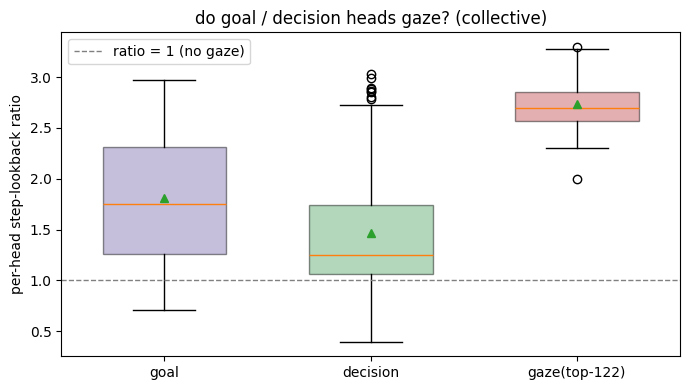

In [10]:
# ── boxplot: goal vs decision vs gaze step-lookback — copied from 09.1 cell 13 ──
GAZE_COLOR = {"goal": "#8172b3", "decision": "#55a868", f"gaze(top-{NGOAL})": "#c44e52"}
fig, ax = plt.subplots(figsize=(7, 4))
data = [set_vals(hs) for hs in GAZE_SETS.values()]
bp = ax.boxplot(data, labels=list(GAZE_SETS), showmeans=True, widths=0.6, patch_artist=True)
for patch, name in zip(bp["boxes"], GAZE_SETS):
    patch.set_facecolor(GAZE_COLOR[name]); patch.set_alpha(0.45)
ax.axhline(1.0, ls="--", c="grey", lw=1, label="ratio = 1 (no gaze)")
ax.set_ylabel("per-head step-lookback ratio")
ax.set_title("do goal / decision heads gaze? (collective)")
ax.legend(); plt.tight_layout()
FIG1B = os.path.join(FIGDIR, "goal_decision_gaze_score.png")
plt.savefig(FIG1B, dpi=110, bbox_inches="tight"); print("saved", FIG1B); plt.show()

## 2. Do decision heads work as goal heads?

`apply_goalscope` with **only** `selected_heads` swapped (decision vs goal) — same prompt, same
`GOALSCOPE_KWARGS`, following `10 §3b`. Run on **two** prompts:

- **code prompt** — the `validate_config` prompt from `10 §3b`, so the goal-head arm is directly
  comparable across notebooks;
- **conditions prompt** — a native `build_example` multiline prompt, the decision heads' own
  training domain (arguably the fairer test *of them*).

If decision heads were doing the goal heads' job, their verbalizations should read like goal
descriptions ("checking the timeout", "handling condition B") rather than move-on/step signals.

In [11]:
from src.goals.data import IncompleteCodeSample
from src.goals.functional import apply_chat_template
from src.goals.goalscope import apply_goalscope, greedy_continue
from src.goals.multiline_prompts import build_example, replace_in_code_newline_with_tabnewline
from src.tokens import prepare_input

# ── prompt A: the clock/10 §3b code prompt ──
messages = [
    {"role": "system", "content": "You are a helpful assistant proficient in programming."},
    {"role": "user", "content": "Write a mergesort code in Python. Just the code, no explanation and comments."},
    {"role": "assistant", "content": "\n<code>\n"},
]
code_prompt = mt.tokenizer.apply_chat_template(
    messages,
    add_generation_prompt=False,
    continue_final_message=True,
    tokenize=False,
    chat_template_kwargs={"enable_thinking": False},
)

_ci = prepare_input(prompts=code_prompt, tokenizer=mt)
code_prompt_full = code_prompt + greedy_continue(mt, _ci["input_ids"], _ci["attention_mask"],
                                                 max_new_tokens=256)

# ── prompt B: a native build_example conditions prompt (decision heads' domain) ──
_ex = build_example(mt=mt, rng=random.Random(1123), target_slot=1, n_conditions=4,
                    mode="chat", style="multiline", naming="letters")
cond_prompt = replace_in_code_newline_with_tabnewline(_ex["full_prompt"]) + "   "
_di = prepare_input(prompts=cond_prompt, tokenizer=mt)
cond_prompt_full = cond_prompt + greedy_continue(mt, _di["input_ids"], _di["attention_mask"],
                                                 max_new_tokens=256)

print("=== code prompt ===");       print(code_prompt_full)
print("\n=== conditions prompt ==="); print(cond_prompt_full)

=== code prompt ===
<|im_start|>system
You are a helpful assistant proficient in programming.<|im_end|>
<|im_start|>user
Write a mergesort code in Python. Just the code, no explanation and comments.<|im_end|>
<|im_start|>assistant

<code>
def merge_sort(arr):
    if len(arr) > 1:
        mid = len(arr) // 2
        L = arr[:mid]
        R = arr[mid:]

        merge_sort(L)
        merge_sort(R)

        i = j = k = 0

        while i < len(L) and j < len(R):
            if L[i] < R[j]:
                arr[k] = L[i]
                i += 1
            else:
                arr[k] = R[j]
                j += 1
            k += 1

        while i < len(L):
            arr[k] = L[i]
            i += 1
            k += 1

        while j < len(R):
            arr[k] = R[j]
            j += 1
            k += 1
</code>

=== conditions prompt ===
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make su

In [12]:
# ── common GoalScope kwargs — tweak here; ONLY `selected_heads` differs between runs ──
GOALSCOPE_KWARGS = dict(
    mt=mt,
    # strategy="replace", alpha=1.0,
    strategy="additive", alpha=0.2,
    batch_size=32,
    max_new_tokens=64,
)

In [14]:
# ── prompt A (code) — DECISION heads ──
code_dec_scope = apply_goalscope(
    code_prompt_full,
    selected_heads=decision_heads,
    title=f"GoalScope | code | decision heads (n={len(dset)})",
    save_path=f"merge_sort_decision_{GOALSCOPE_KWARGS['strategy']}.html",
    **GOALSCOPE_KWARGS,
)

GoalScope[additive]:   0%|          | 0/7 [00:00<?, ?it/s]

Saved -> merge_sort_decision_additive.html


In [15]:
# ── prompt A (code) — GOAL heads ──
code_goal_scope = apply_goalscope(
    code_prompt_full,
    selected_heads=goal_heads,
    title=f"GoalScope | code | goal heads (n={len(gset)})",
    save_path=f"merge_sort_goal_{GOALSCOPE_KWARGS['strategy']}.html",
    **GOALSCOPE_KWARGS,
)

GoalScope[additive]:   0%|          | 0/7 [00:00<?, ?it/s]

Saved -> merge_sort_goal_additive.html


In [16]:
# ── prompt B (conditions) — DECISION heads ──
cond_dec_scope = apply_goalscope(
    cond_prompt_full,
    selected_heads=decision_heads,
    title=f"GoalScope | conditions | decision heads (n={len(dset)})",
    save_path=f"multistep_decision_{GOALSCOPE_KWARGS['strategy']}.html",
    include_noncode=True,
    **GOALSCOPE_KWARGS,
)

GoalScope[additive]:   0%|          | 0/5 [00:00<?, ?it/s]

Saved -> multistep_decision_additive.html


In [17]:
# ── prompt B (conditions) — GOAL heads ──
cond_goal_scope = apply_goalscope(
    cond_prompt_full,
    selected_heads=goal_heads,
    title=f"GoalScope | conditions | goal heads (n={len(gset)})",
    save_path=f"multistep_goal_{GOALSCOPE_KWARGS['strategy']}.html",
    **GOALSCOPE_KWARGS,
)

GoalScope[additive]:   0%|          | 0/5 [00:00<?, ?it/s]

Saved -> multistep_goal_additive.html


## 3. Do goal heads work as decision heads?

The `09.1 §2a` move-on transplant, with the intervention mask swapped: inject `mean_src` (the
general move-on signal) at `PATCH_POS` into **decision heads** (reference arm) vs **goal heads**
(test arm). Because the decision mask spans all 64 layers, `mean_src` already covers the goal band —
the swap is `get_mask_bin(dset)` → `get_mask_bin(gset)`, nothing else changes.

Three readouts per arm: **generation**, **next-token prediction**, and **gaze/attention**.

The attention readout is displayed on a fixed `READOUT_HEADS` set (goal heads by default) so both
arms are read the same way — the *intervention* head set is what varies. `ALPHA` is the knob to
play with.

In [21]:
from src.functional import predict_next_token, interpret_logits, generate_with_patch
from src.goals.head_loc_attn import forward_with_src_replacement
from src.goals.goalscope import headpatched_generate

# ── dest: a staying (`ml`) prompt — copied from 09.1 cell 19 ──
N_GEN = 64
dest_example = build_example(mt=mt, rng=random.Random(1123), target_slot=1, n_conditions=4,
                             mode="chat", style="multiline", naming="letters")
dest_prompt = replace_in_code_newline_with_tabnewline(dest_example["full_prompt"]) + "   "
dest_tok = prepare_input(dest_prompt, tokenizer=mt, padding_side="left")

clean_gen = generate_with_patch(mt, inputs=dest_tok, n_gen_per_prompt=1, max_new_tokens=N_GEN,
                                do_sample=False, remove_prefix=True)[0]
rich_print(f"[bold]clean        [/bold] [white]{escape(dest_prompt)}[/white]"
           f"[sea_green3]{escape(clean_gen)}[/sea_green3]")
clean_top_pred = predict_next_token(mt=mt, inputs=dest_tok)
clean_top_pred

clean         <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n has at least 4 digits
2. n has more than 1 ones in its binary representation
3. n has more than 6 divisors
4. n is even

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = len(str(abs(n)))    
    a = a >= 4    
    b = bin(abs(n)).count("1")    
    b = b > 1    
    c = sum(1 for i in range(1, abs(n) + 1) if abs(n) % i == 0)    
    c = c > 6    
    d = n % 2 == 0    
    print(f"Condition 1

[[PredictedToken(token=' b', prob=1.0, logit=31.75, token_id=293, metadata=None),
  PredictedToken(token=' c', prob=2.905726432800293e-06, logit=19.0, token_id=272, metadata=None),
  PredictedToken(token=' d', prob=6.007030606269836e-08, logit=15.125, token_id=294, metadata=None),
  PredictedToken(token=' B', prob=3.026798367500305e-08, logit=14.4375, token_id=425, metadata=None),
  PredictedToken(token='\tb', prob=2.0838342607021332e-08, logit=14.0625, token_id=2233, metadata=None)]]

In [31]:
# ── the transplant, once per intervention head set — copied from 09.1 cell 20, mask swapped ──
ALPHA = 2.0  # <- knob: tune freely
ARMS = {"decision": decision_heads, "goal": goal_heads}

patched_gen, patched_pred = {}, {}
for name, heads in ARMS.items():
    patched_gen[name] = headpatched_generate(
        mt,
        dest_inputs=dest_tok,
        src_o_proj_inps=mean_src,
        mask=get_mask_bin(heads),
        layers=list(range(mt.n_layer)),
        max_new_tokens=N_GEN,
        n_steer_tokens=1,
        patch_input_positions=[PATCH_POS],
        alpha=ALPHA,
    )
    logits = forward_with_src_replacement(
        mt,
        dest_inputs=dest_tok,
        mask=get_mask_bin(heads),
        src_head_inps=mean_src,
        layers=list(range(mt.n_layer)),
        patch_positions=[PATCH_POS],
        alpha=ALPHA,
    )
    patched_pred[name] = interpret_logits(tokenizer=mt, logits=logits)

rich_print(
    f"[bold]clean            [/bold] [white]{escape(dest_prompt)}[/white]"
    f"[sea_green3]{escape(clean_gen)}[/sea_green3]\n"
)
for name in ARMS:
    rich_print(
        f"[bold]patched {name:9s}[/bold] (n={len(ARMS[name])}, alpha={ALPHA}) "
        f"[white]{escape(dest_prompt)}[/white][salmon1]{escape(patched_gen[name])}[/salmon1]\n"
    )

pt = Table(title=f"next-token prediction at the pivot (alpha={ALPHA})")
pt.add_column("arm")
pt.add_column("top prediction")
pt.add_row("clean", str([str(pred) for pred in clean_top_pred[0]]))
for name in ARMS:
    pt.add_row(f"patched {name}", str([str(pred) for pred in patched_pred[name]]))
rich_print(pt)

clean             <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n has at least 4 digits
2. n has more than 1 ones in its binary representation
3. n has more than 6 divisors
4. n is even

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = len(str(abs(n)))    
    a = a >= 4    
    b = bin(abs(n)).count("1")    
    b = b > 1    
    c = sum(1 for i in range(1, abs(n) + 1) if abs(n) % i == 0)    
    c = c > 6    
    d = n % 2 == 0    
    print(f"Condition 1

patched decision  (n=181, alpha=2.0) <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n has at least 4 digits
2. n has more than 1 ones in its binary representation
3. n has more than 6 divisors
4. n is even

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = len(str(abs(n)))    
    a = a >= 4    
    b = bin(abs(n)).count("1")    
    c = sum(1 for i in range(1, abs(n) + 1) if abs(n) % i == 0)    
    c = c > 6    
    d = n % 2 == 0    
    print(f"Condition 1: {a}, Condition 2:

patched goal      (n=122, alpha=2.0) <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n has at least 4 digits
2. n has more than 1 ones in its binary representation
3. n has more than 6 divisors
4. n is even

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = len(str(abs(n)))    
    a = a >= 4    
    b = bin(abs(n)).count("1")    
    b = b > 1    
    c = sum(1 for i in range(1, abs(n) + 1) if abs(n) % i == 0)    
    c = c > 6    
    d = n % 2 == 0    
    print(f"Condition 1

                                  next-token prediction at the pivot (alpha=2.0)                                   
┏━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ arm              ┃ top prediction                                                                               ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ clean            │ ["' b' [293] (p=1.000, logit=31.750)", "' c' [272] (p=0.000, logit=19.000)", "' d' [294]     │
│                  │ (p=0.000, logit=15.125)", "' B' [425] (p=0.000, logit=14.438)", "'\\tb' [2233] (p=0.000,     │
│                  │ logit=14.062)"]                                                                              │
│ patched decision │ ["' c' [272] (p=0.988, logit=25.500)", "' d' [294] (p=0.011, logit=21.000)", "' div' [3429]  │
│                  │ (p=0.000, logit=17.000)", "' i' [600] (p=0.000, logit=16.875)", "' count' [1760] (p=0.000,   │
│                  │ logit=16.625)"]                                                                              │
│ patched goal     │ ["' b' [293] (p=1.000, logit=28.750)", "' c' [272] (p=0.000, logit=20.125)", "' d' [294]     │
│                  │ (p=0.000, logit=16.625)", "' e' [384] (p=0.000, logit=14.812)", "' if' [421] (p=0.000,       │
│                  │ logit=14.438)"]                                                                              │
└──────────────────┴──────────────────────────────────────────────────────────────────────────────────────────────┘

In [32]:
# ── attention readout: clean — copied from 09.1 cell 21 ──
from src.attention import get_attention_matrices, show_interactive_attention
from src.goals.head_loc_attn import make_head_replacement_patch_interface

READOUT_HEADS = goal_heads      # <- heads the gaze is READ on (same for both arms)

P_py = len(dest_tok.input_ids[0])
pivot_abs_py = P_py + PATCH_POS

_clean_ids = prepare_input(dest_prompt + clean_gen, tokenizer=mt).input_ids[0]
assert _clean_ids[:P_py].tolist() == dest_tok.input_ids[0].tolist(), (
    "retokenization drift: dest_prompt is not a clean prefix of dest_prompt + clean_gen"
)

clean_attn = get_attention_matrices(input=dest_prompt + clean_gen, mt=mt, value_weighted=True)
show_interactive_attention(
    attn_info=clean_attn, selected_heads=sorted(READOUT_HEADS), start_from=0,
    agg="mean", normalize="row_max", cmap="Greens",
    title=f"clean attention — readout on {len(READOUT_HEADS)} goal heads",
    track_conditions=dest_example["spec"], intervened_positions=[pivot_abs_py], height=None,
)

'<!DOCTYPE html>\n<html><head><meta charset="utf-8"><title>clean attention — readout on 122 goal heads</title>\n<style>\n #iaviz-a241797b { font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Helvetica, Arial, sans-serif;\n            background: #fafafa; color: #111; padding: 12px; border-radius: 6px; }\n #iaviz-a241797b h2 { margin: 4px 0 6px 0; font-size: 16px; font-weight: 600; color: #111; }\n #iaviz-a241797b .meta { color: #555; font-size: 12px; margin-bottom: 10px; }\n #iaviz-a241797b .head-list { color: #777; font-size: 11px; margin-bottom: 14px; font-family: monospace; }\n #iaviz-a241797b .tokens {\n   font-family: ui-monospace, "SF Mono", Menlo, Consolas, monospace;\n   font-size: 13px;\n   line-height: 1.85;\n   background: #fff;\n   border: 1px solid #ddd;\n   border-radius: 6px;\n   padding: 14px 16px;\n   white-space: pre-wrap;\n   word-break: break-word;\n }\n #iaviz-a241797b .tok {\n   display: inline-block;\n   padding: 2px 4px;\n   margin: 1px 0;\n   b

In [33]:
# ── attention readout: patched, per arm — copied from 09.1 cell 21, mask swapped ──
def show_patched_attention(name):
    heads = ARMS[name]
    gen = patched_gen[name]
    ids = prepare_input(dest_prompt + gen, tokenizer=mt).input_ids[0]
    assert ids[:P_py].tolist() == dest_tok.input_ids[0].tolist(), (
        f"retokenization drift on the {name} arm"
    )
    iface = make_head_replacement_patch_interface(
        src_head_inps=mean_src, mask=get_mask_bin(heads),
        layers=list(range(mt.n_layer)), patch_positions=[pivot_abs_py], alpha=ALPHA,
    )
    attn = get_attention_matrices(input=dest_prompt + gen, mt=mt,
                                  value_weighted=True, patch_interface=iface)
    show_interactive_attention(
        attn_info=attn, selected_heads=sorted(READOUT_HEADS), start_from=0,
        agg="mean", normalize="row_max", cmap="Reds",
        title=f"move-on transplant into {name} heads (n={len(heads)}, alpha={ALPHA}) — "
              f"readout on {len(READOUT_HEADS)} goal heads",
        track_conditions=dest_example["spec"], intervened_positions=[pivot_abs_py],
        height=None, condition_agg="mean",
    )

show_patched_attention("decision")

In [34]:
show_patched_attention("goal")

## 4. Scale-up — the letter oracle at the pivot (`naming="letters"`, pivot −2 only)

With `naming="letters"` the conditions are assigned to `a`, `b`, `c`, … in order, so "did the model
move on?" has a **cheap programmatic oracle**: at the pivot, does the next line start with the
**next** letter (moved on, `sl`-like) or the **current** one (stayed, `ml`-like)?

The pivot token *is* the variable letter — in the §3 demo the clean model emits ` b` at p≈1.0 with
` c` as runner-up — so this needs **one forward pass per arm**, not a 64-token generation.

Three arms, all at `PATCH_POS = -2`: **clean**, transplant into **decision** heads, transplant into
**goal** heads. Metrics per prompt:

- **move-on (argmax)** — full-vocab argmax is the next letter;
- **move-on (2-way)** — `p(next) > p(current)`, ignoring all other tokens;
- **log-ratio** — `log p(next) − log p(current)`, and its shift vs clean;
- **hard flip** — clean stayed but the patched arm moved on (the `09.1 §2b` definition).

If the goal heads were functioning as decision heads, their move-on rate should track the decision
arm's rather than the clean baseline's.

In [36]:
# ── §4: scale-up — letter oracle at the pivot, clean vs decision-patched vs goal-patched ──
# naming="letters" => condition k is assigned to chr(97+k).  At the pivot the model emits the
# variable letter of the line it is about to write, so "moved on" == that token is the NEXT letter.
# One forward pass per arm per batch; PATCH_POS (-2) only.
import pandas as pd
from tqdm.auto import tqdm

N_SCALE  = 256
N_COND   = 5
ALPHA_SC = ALPHA        # same transplant scale as the §3 demo
BATCH    = 8

def first_tok_id(prompt, letter):
    """Contextualized id of the first token of ' <letter>' right after `prompt`."""
    src = mt.tokenizer(prompt, add_special_tokens=False)["input_ids"]
    tgt = mt.tokenizer(prompt + f" {letter}", add_special_tokens=False)["input_ids"]
    assert len(tgt) > len(src), f"' {letter}' added no token"
    return int(tgt[len(src)])

# ── build the instance pool: staying (`ml`) prompts with a visible next condition ──
rng = random.Random(2025)
insts, attempts = [], 0
while len(insts) < N_SCALE and attempts < N_SCALE * 4:
    attempts += 1
    cur = rng.randint(1, N_COND - 2)                 # staying on `cur`; target = cur+1
    ex = build_example(mt=mt, rng=rng, target_slot=cur, n_conditions=N_COND,
                       mode="chat", style="multiline", naming="letters")
    dp = replace_in_code_newline_with_tabnewline(ex["full_prompt"]) + "   "
    try:
        cid = first_tok_id(dp, chr(97 + cur))        # current letter (stay)
        nid = first_tok_id(dp, chr(97 + cur + 1))    # next letter    (move on)
    except AssertionError:
        continue
    if cid == nid:
        continue
    insts.append((dp, cid, nid, cur))
print(f"built {len(insts)} instances ({attempts} attempts)")

# ── one forward per arm per batch ──
recs = []
for s in tqdm(range(0, len(insts), BATCH), desc="scale-up"):
    chunk = insts[s:s + BATCH]
    B = len(chunk)
    toks = prepare_input(prompts=[c[0] for c in chunk], tokenizer=mt, padding_side="left")
    with torch.inference_mode():
        logit_by_arm = {"clean": mt._model(**dict(toks)).logits[:, -1, :].float()}
        src3 = mean_src.unsqueeze(0).expand(B, -1, -1).contiguous()   # (B, L, n_embd)
        for name, heads in ARMS.items():
            lg = forward_with_src_replacement(
                mt, dest_inputs=toks, mask=get_mask_bin(heads), src_head_inps=src3,
                layers=list(range(mt.n_layer)), patch_positions=[PATCH_POS], alpha=ALPHA_SC,
            )
            if lg.ndim == 1: lg = lg.unsqueeze(0)
            logit_by_arm[name] = lg.float()
    for arm, lg in logit_by_arm.items():
        assert lg.shape[0] == B, f"{arm}: expected batch {B}, got {tuple(lg.shape)}"
        probs = torch.softmax(lg, dim=-1)
        for j, (_dp, cid, nid, cur) in enumerate(chunk):
            p = probs[j]
            p_cur, p_nxt = float(p[cid]), float(p[nid])
            recs.append(dict(
                idx=s + j, arm=arm, cur=cur,
                p_cur=p_cur, p_nxt=p_nxt,
                log_ratio=float(np.log(max(p_nxt, 1e-30)) - np.log(max(p_cur, 1e-30))),
                moved_on_hard=bool(int(p.argmax()) == nid),
                moved_on_2way=bool(p_nxt > p_cur),
            ))

scale_df = pd.DataFrame(recs)
print(f"{len(scale_df)} rows = {scale_df.idx.nunique()} prompts x {scale_df.arm.nunique()} arms")


built 256 instances (256 attempts)


scale-up:   0%|          | 0/32 [00:00<?, ?it/s]

768 rows = 256 prompts x 3 arms


                             move-on at the pivot (alpha=2.0, N=256 prompts, pivot=-2)                             
┏━━━━━━━━━━┳━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃          ┃     ┃                  ┃                 ┃          mean log ┃    Δ log-ratio vs ┃      hard flip vs ┃
┃ arm      ┃   n ┃ move-on (argmax) ┃ move-on (2-way) ┃    p(next)/p(cur) ┃             clean ┃             clean ┃
┡━━━━━━━━━━╇━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ clean    │ 256 │            0.047 │           0.086 │            -5.915 │                 — │                 — │
│ decision │ 256 │            0.977 │           1.000 │           +10.059 │           +15.974 │             0.975 │
│ goal     │ 256 │            0.152 │           0.191 │            -2.871 │            +3.044 │             0.123 │
└──────────┴─────┴──────────────────┴─────────────────┴───────────────────┴───────────────────┴───────────────────┘

saved /disk/u/arnab/Codes/Projects/goals/results/dissociation/Qwen2.5-Coder-32B-Instruct/goal_vs_decision_moveon.png


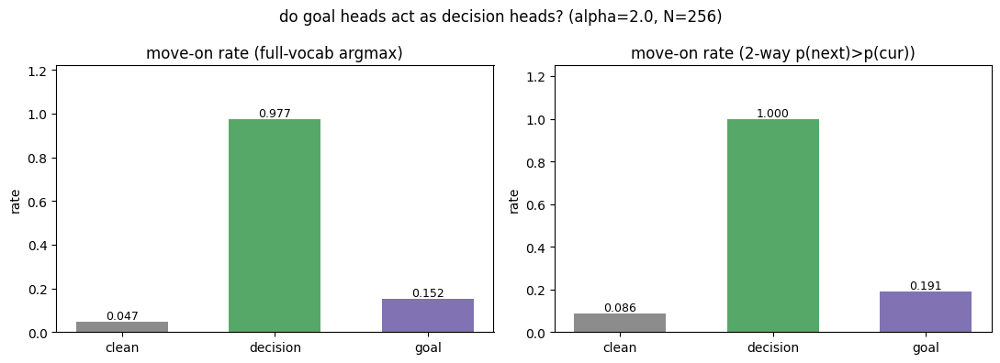

move-on rate: clean=0.047  decision=0.977  goal=0.152

goal recovers 11% of the decision-head effect (0% = behaves like clean, 100% = behaves like decision heads)

In [37]:
# ── §4 summary: move-on rates per arm + flip vs clean ──
ARM_ORDER = ["clean", "decision", "goal"]
ARM_COLOR = {"clean": "#8c8c8c", "decision": "#55a868", "goal": "#8172b3"}

clean_df = scale_df[scale_df.arm == "clean"].set_index("idx")

t = Table(title=f"move-on at the pivot (alpha={ALPHA_SC}, N={scale_df.idx.nunique()} prompts, pivot={PATCH_POS})")
for c in ["arm", "n", "move-on (argmax)", "move-on (2-way)", "mean log p(next)/p(cur)",
          "Δ log-ratio vs clean", "hard flip vs clean"]:
    t.add_column(c, justify=("left" if c == "arm" else "right"))
for arm in ARM_ORDER:
    g = scale_df[scale_df.arm == arm].set_index("idx")
    d_lr = float((g.log_ratio - clean_df.log_ratio).mean())
    if arm == "clean":
        flip = float("nan")
    else:
        stayed = clean_df[~clean_df.moved_on_hard].index          # clean did NOT move on
        flip = float(g.loc[stayed].moved_on_hard.mean()) if len(stayed) else float("nan")
    t.add_row(arm, str(len(g)), f"{g.moved_on_hard.mean():.3f}", f"{g.moved_on_2way.mean():.3f}",
              f"{g.log_ratio.mean():+.3f}", "—" if arm == "clean" else f"{d_lr:+.3f}",
              "—" if flip != flip else f"{flip:.3f}")
rich_print(t)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
xs = np.arange(len(ARM_ORDER))
for ax, col, lbl in zip(axes, ["moved_on_hard", "moved_on_2way"],
                        ["move-on rate (full-vocab argmax)", "move-on rate (2-way p(next)>p(cur))"]):
    vals = [scale_df[scale_df.arm == a][col].mean() for a in ARM_ORDER]
    ax.bar(xs, vals, color=[ARM_COLOR[a] for a in ARM_ORDER], width=0.6)
    for x, v in zip(xs, vals):
        ax.text(x, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(xs); ax.set_xticklabels(ARM_ORDER)
    ax.set_ylim(0, max(max(vals) * 1.25, 0.05)); ax.set_ylabel("rate"); ax.set_title(lbl)
plt.suptitle(f"do goal heads act as decision heads? (alpha={ALPHA_SC}, N={scale_df.idx.nunique()})")
plt.tight_layout()
FIG4 = os.path.join(FIGDIR, "goal_vs_decision_moveon.png")
plt.savefig(FIG4, dpi=110, bbox_inches="tight"); print("saved", FIG4); plt.show()

# ── crude read: is the goal arm closer to decision, or to clean? ──
r = {a: scale_df[scale_df.arm == a].moved_on_hard.mean() for a in ARM_ORDER}
span = r["decision"] - r["clean"]
frac = (r["goal"] - r["clean"]) / span if abs(span) > 1e-9 else float("nan")
rich_print(f"[bold]move-on rate:[/bold] clean={r['clean']:.3f}  decision={r['decision']:.3f}  goal={r['goal']:.3f}")
rich_print(f"[bold]goal recovers {frac:.0%} of the decision-head effect[/bold] "
           f"(0% = behaves like clean, 100% = behaves like decision heads)"
           if frac == frac else "[bold]decision arm shows no effect over clean — ratio undefined[/bold]")
